# M12.1 — Paired G1 validation evaluation

Evaluate the completed M12.1a weighted-MSE checkpoint against frozen M11 on the **same 40000 G1 validation rows**. Training runs elsewhere; this notebook never trains, predicts, or watches that job. Delivered unexecuted with no results. Only this notebook is created; analysis writes no files.

Reuse [M12.0](M12_0_frozen_baseline_and_acceptance.ipynb), its frozen JSON reference, [M12.1 preparation](M12_1_weighted_mse.ipynb), `src.paths`, and `src.models.evaluate`. Freeze G1 preprocessing, normalization, label scaler, architecture and row memberships. Load no signals, embeddings, calibration/test predictions, or real-event artifacts. Training labels are read solely to reconstruct the frozen reference CDF and the new descriptive marginal CDFs. No evaluation labels fit a training reference.

Validation supports candidate assessment; do not repeatedly select against the frozen test. Validation has already selected each checkpoint by unweighted standardized MSE, so its comparison is not an independent final generalization estimate. The marginal diagnostics below must not modify the running experiment, its loss, or its weights retroactively.

## 1. Configuration, provenance and strict row alignment
Set `M12_VALIDATION_PATH` to the actual completed prediction archive; no future filename is assumed. An absolute path or a path relative to the existing `DATA_ROOT` is accepted. `DATA_ROOT` uses the existing `src.paths.resolve_data_root` convention (environment override, then frozen M11 config), with no new root variable convention.

Both trusted project NPZs must contain `pred_val`, `y_val` (standardized, N×3), `idx_val` (original integer HDF5 row IDs), `y_mean`, `y_std`, `label_names`, `available_splits`, `checkpoint_file`, `dataset_path`, `split_path`, `label_stats_path`, `model_config`, and `input_normalization`. Embeddings are unnecessary and remain unread. `model_config` must retain the checkpoint's class/kwargs, labels, normalization, seed and dataset metadata; M12 must also retain `sample_weighting` provenance. Object dictionaries require `allow_pickle=True`: load only trusted project artifacts.

Expected checkpoint names are derived from the existing M11 and M12.1a configs. A different candidate/config needs explicit review, not a fallback glob or latest-file selection. Provenance checks establish consistency with recorded metadata, not independent cryptographic identity of checkpoint bytes. The notebook records hashes of prediction arrays and small contracts; it never deserializes checkpoints. Physical units follow the verified saved scaler/HDF5 label contract: masses in solar masses and dimensionless chi_eff, not real-event frame conversions.

In [1]:
from pathlib import Path
import sys, json, hashlib, copy
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open from the cbc_pe repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
from src.models.evaluate import regression_metrics, inverse_standardize
from src.models.sample_weighting import array_hash

CONFIG_PATHS = {"M11": ROOT / "configs/experiments/train_m11_final_G1_500k.json",
                "M12.1": ROOT / "configs/experiments/train_m12_1a_weighted_mse.json"}
configs = {m:json.loads(p.read_text()) for m,p in CONFIG_PATHS.items()}
DATA_ROOT = resolve_data_root(config_data_root=configs["M11"].get("data_root"))
DATASET_ID = "M11_final_G1_500k"
LABELS = ["chirp_mass", "total_mass", "chi_eff"]
UNITS = ["Msun", "Msun", "dimensionless"]
MODELS = ["M11", "M12.1"]
RESULTS = DATA_ROOT / "results" / DATASET_ID

M12_VALIDATION_PATH = ( DATA_ROOT / "results" /  # REQUIRED: actual NPZ path, absolute or relative to DATA_ROOT.
"M11_final_G1_500k" / 
"m12_1_G1_val_predictions_embeddings.npz"
)  
BOOTSTRAP_COUNT = 400
BOOTSTRAP_SEED = 123
RUN_BOOTSTRAP = True  # Explicit opt-in before manually executing section 7.
MIN_COUNT = 30
MIN_2D_COUNT = 100
PERIPHERAL_MASS_MAX_DEGRADATION = 0.02  # Fraction, scientific tolerance not yet specified.

M11_VALIDATION_PATH = RESULTS / "m11_final_G1_500k_val_predictions_embeddings.npz"
CONTRACT_PATH = ROOT / "notebooks/m12/outputs/m12_0_baseline_contract.json"
PATHS = {key:resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
    file_name=configs["M11"]["dataset"][key], allow_legacy_flat=False)
    for key in ("dataset_file", "split_file", "label_stats_file")}

def require(ok, message):
    if not ok:
        raise ValueError(message)

def file_record(path, small=False):
    path = Path(path)
    require(path.is_file(), f"Missing frozen input: {path}; no generation fallback")
    st = path.stat()
    record = dict(path=str(path), size=st.st_size, mtime_ns=st.st_mtime_ns)
    if small:
        record["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return record

require(M12_VALIDATION_PATH is not None, "Set M12_VALIDATION_PATH after validation predictions exist")
m12_path = Path(M12_VALIDATION_PATH).expanduser()
if not m12_path.is_absolute():
    m12_path = DATA_ROOT / m12_path
prediction_paths = {"M11":M11_VALIDATION_PATH, "M12.1":m12_path}
require(m12_path.resolve() != M11_VALIDATION_PATH.resolve(), "Candidate and baseline paths coincide")
expected = copy.deepcopy(configs["M11"])
expected.pop("data_root", None)
expected["training"]["sample_weighting"] = dict(method="train_label_mahalanobis", alpha=.5,
                                                normalization="train_mean_one")
expected["outputs"] = configs["M12.1"]["outputs"]
actual = copy.deepcopy(configs["M12.1"])
actual.pop("data_root", None)
require(actual == expected, "Candidate config changes more than sample weights/output destination")
require(configs["M12.1"]["outputs"]["checkpoint_tag"].startswith("M12_1"), "Wrong candidate tag")
# Use geometry/definitions only; historical test metrics and real-event results are not evaluated.
frozen = json.loads(CONTRACT_PATH.read_text())
require(frozen["schema_version"] == 1 and frozen["dataset_id"] == DATASET_ID
        and frozen["labels"] == LABELS, "Wrong M12.0 contract")
# Pin the small split/scaler contracts as well as train geometry; do not trust filenames alone.
for key in ("split_file", "label_stats_file"):
    require(file_record(PATHS[key], True)["sha256"] ==
            frozen["provenance"]["local_artifacts"][key]["sha256"],
            f"Frozen M12.0 artifact content mismatch: {key}")
geometry = frozen["geometry"]
P_EDGES = np.asarray(geometry["edges"], dtype=float)
SNR_EDGES = np.asarray(frozen["definitions"]["snr_edges"], dtype=float)
require(np.array_equal(P_EDGES, [0,20,40,60,80,100]), "Changed percentile bins")
require(np.array_equal(SNR_EDGES, [10,12.5,15,17.5,20,22.5,25]), "Changed SNR bins")
del frozen
provenance = dict(contract=file_record(CONTRACT_PATH, True),
    configs={m:file_record(p, True) for m,p in CONFIG_PATHS.items()},
    artifacts={k:file_record(p, k != "dataset_file") for k,p in PATHS.items()},
    predictions={m:file_record(p) for m,p in prediction_paths.items()},
    split="val", units=dict(zip(LABELS, UNITS)))

In [2]:
with np.load(PATHS["split_file"], allow_pickle=False) as z:
    train_ids = np.sort(z["train_idx"].copy())
    val_ids = np.sort(z["val_idx"].copy())
    require(int(z["seed"].item()) == 123, "Split seed changed")
for name, ids, n in (("train",train_ids,400000), ("val",val_ids,40000)):
    require(ids.shape == (n,) and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == n and ((ids >= 0) & (ids < 500000)).all(), f"Invalid {name} IDs")
require(np.intersect1d(train_ids, val_ids).size == 0, "Train/validation overlap")
require(array_hash(train_ids) == geometry["train_indices_sha256"], "Changed frozen train rows")
with np.load(PATHS["label_stats_file"], allow_pickle=False) as z:
    mean, std = z["y_mean"].copy(), z["y_std"].copy()
    require(z["label_names"].tolist() == LABELS, "Scaler label order")
    require(np.array_equal(np.sort(z["train_idx"]), train_ids), "Scaler train membership")
require(mean.shape == std.shape == (3,) and np.isfinite(mean).all()
        and np.isfinite(std).all() and (std > 0).all(), "Invalid saved scaler")

def load_validation(model):
    cfg = configs[model]
    checkpoint_name = (f"{DATASET_ID}_{cfg['model']['class_name']}_"
        f"{cfg['outputs']['checkpoint_tag']}_{cfg['training']['loss']}_seed123_checkpoint.pt")
    with np.load(prediction_paths[model], allow_pickle=True) as z:
        needed = {"pred_val", "y_val", "idx_val", "y_mean", "y_std", "label_names", "available_splits",
                  "checkpoint_file", "dataset_path", "split_path", "label_stats_path",
                  "model_config", "input_normalization"}
        require(needed <= set(z.files), f"{model}: missing {needed-set(z.files)}")
        require(z["available_splits"].tolist() == ["val"], "Require a validation-only prediction archive")
        require(z["label_names"].tolist() == LABELS, "Prediction label order")
        require(np.array_equal(z["y_mean"], mean) and np.array_equal(z["y_std"], std), "Scaler changed")
        saved = {k:z[k].item() for k in ("checkpoint_file", "dataset_path", "split_path",
                  "label_stats_path", "model_config", "input_normalization")}
        require(Path(saved["checkpoint_file"]).name == checkpoint_name, "Wrong recorded checkpoint")
        for key, local in (("dataset_path","dataset_file"), ("split_path","split_file"),
                           ("label_stats_path","label_stats_file")):
            require(Path(saved[key]).name == PATHS[local].name, "Recorded artifact mismatch")
        mc = saved["model_config"]
        require(mc["dataset_id"] == DATASET_ID and mc["label_names"] == LABELS, "Checkpoint dataset/labels")
        require(mc["class_name"] == cfg["model"]["class_name"]
                and mc["model_kwargs"] == cfg["model"]["kwargs"], "Checkpoint architecture changed")
        require(mc["training_seed"] == 123 and mc["split_seed"] == 123, "Checkpoint seeds changed")
        require(mc["train_size"] == 400000 and mc["val_size"] == 40000, "Checkpoint split sizes")
        require(saved["input_normalization"] == mc["input_normalization"] == cfg["input_normalization"],
                "Input normalization changed")
        if model == "M12.1":
            w = mc["sample_weighting"]
            for key, value in cfg["training"]["sample_weighting"].items():
                require(w[key] == value, f"Weight provenance: {key}")
            for key in ("train_indices_sha256", "reference_distance_sha256", "n_train", "rank"):
                require(w[key] == geometry[key], f"Training reference differs from M12.0: {key}")
            require(w["validation_objective"] == "unweighted standardized MSELoss", "Weighted validation objective")
        ids, truth_std, pred_std = (z[k].copy() for k in ("idx_val", "y_val", "pred_val"))
    require(ids.shape == val_ids.shape and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == len(ids), "Duplicate or malformed prediction IDs")
    require(np.array_equal(np.sort(ids), val_ids), "Prediction archive does not cover exact validation membership")
    require(truth_std.shape == pred_std.shape == (len(ids),3)
            and np.isfinite(truth_std).all() and np.isfinite(pred_std).all(), "Invalid predictions/targets")
    # Reindex each archive independently by original row ID, never zip raw rows.
    order = np.argsort(ids)
    truth_std, pred_std = truth_std[order], pred_std[order]
    provenance["predictions"][model].update(saved=saved, ordered_ids_sha256=array_hash(val_ids),
        truth_sha256=array_hash(truth_std), prediction_sha256=array_hash(pred_std))
    return dict(truth_std=truth_std,
        truth=inverse_standardize(truth_std, mean, std).astype(np.float64),
        pred=inverse_standardize(pred_std, mean, std).astype(np.float64))

loaded = {m:load_validation(m) for m in MODELS}
require(np.array_equal(loaded["M11"]["truth_std"], loaded["M12.1"]["truth_std"]), "Paired truth mismatch")
y_true = loaded["M11"]["truth"]
predictions = {m:loaded[m]["pred"] for m in MODELS}

def read_rows(dataset, ids):
    result = np.empty((len(ids), *dataset.shape[1:]), dtype=np.float64)
    for start in range(0, len(ids), 4096):
        result[start:start+4096] = dataset[ids[start:start+4096]]
    return result

snr, snr_issue = None, None
with h5py.File(PATHS["dataset_file"], "r") as h:
    require(h.attrs.get("experiment_id") == DATASET_ID
            and h.attrs.get("labels") == ",".join(LABELS), "HDF5 identity/labels")
    require(h["y"].shape == (500000,3), "Wrong G1 label dimensions")
    membership = h["split"].asstr()[:]
    require(np.array_equal(np.flatnonzero(membership == "train"), train_ids)
            and np.array_equal(np.flatnonzero(membership == "val"), val_ids), "HDF5 split membership")
    physical_val = read_rows(h["y"], val_ids)
    require(np.allclose(physical_val, y_true, rtol=2e-6, atol=2e-5), "Physical units/row pairing mismatch")
    train_y = read_rows(h["y"], train_ids)
    if ("final_network_snr" in h and h.attrs.get("snr_low_frequency_cutoff") == 30.
            and h.attrs.get("snr_high_frequency_cutoff") == 512.):
        require(h["final_network_snr"].shape == (500000,), "Wrong SNR shape")
        snr = read_rows(h["final_network_snr"], val_ids)
        require(np.isfinite(snr).all() and (snr >= 0).all(), "Invalid SNR")
    else:
        snr_issue = "final_network_snr or 30–512 Hz definition unavailable; no replacement allowed"
del physical_val, membership, loaded
require(np.isfinite(train_y).all() and np.isfinite(y_true).all()
        and all(np.isfinite(p).all() for p in predictions.values()), "Nonfinite physical arrays")
residuals = {m:p-y_true for m,p in predictions.items()}
provenance["ordered_val_ids_sha256"] = array_hash(val_ids)
provenance["snr_status"] = snr_issue or "verified final_network_snr, optimal 30–512 Hz"
display(pd.DataFrame([dict(model=m, n=len(val_ids), checkpoint=provenance["predictions"][m]["saved"]["checkpoint_file"],
    ids_sha256=provenance["ordered_val_ids_sha256"]) for m in MODELS]))

,model,n,checkpoint,ids_sha256
0,M11,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
1,M12.1,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...


## 2. Global evaluation and focused plots
All errors are physical-unit errors; residual = prediction − truth. Reuse historical RMSE/MAE/R²/bias definitions. OLS is prediction = slope × truth + intercept. Delta always means **M12.1 − M11**; negative is favorable for RMSE/MAE and slope distance, while signed bias alone has no universal favorable sign. R² increases are favorable.

One 2×3 figure overlays both models' truth/prediction scatterplots on a deterministic ≤2000-row display subset and shows full-validation residual means and 16–84% residual spread in common truth deciles. Spread is not a confidence interval. All metrics use all rows; plots do not change any fitted quantity.

,model,label,unit,n,RMSE,MAE,R2,bias,slope,intercept,slope_distance
0,M11,chirp_mass,Msun,40000,5.827355,3.949443,0.875498,0.078911,0.835143,6.239254,0.164857
1,M11,total_mass,Msun,40000,10.597668,7.543623,0.906696,0.379522,0.859322,13.720368,0.140678
2,M11,chi_eff,dimensionless,40000,0.194330,0.145279,0.804043,-0.005354,0.776008,-0.005369,0.223992
3,M12.1,chirp_mass,Msun,40000,5.797211,3.938447,0.876782,0.447505,0.852194,5.970662,0.147806
4,M12.1,total_mass,Msun,40000,10.490344,7.530605,0.908576,1.280246,0.879102,12.745321,0.120898
5,M12.1,chi_eff,dimensionless,40000,0.194161,0.145742,0.804383,-0.002470,0.780751,-0.002484,0.219249


,delta_RMSE,delta_MAE,delta_R2,delta_bias,delta_slope_distance,relative_RMSE_change
label,,,,,,
chirp_mass,-0.030144,-0.010996,0.001285,0.368594,-0.017052,-0.005173
total_mass,-0.107324,-0.013018,0.001880,0.900724,-0.019780,-0.010127
chi_eff,-0.000169,0.000463,0.000340,0.002885,-0.004743,-0.000867


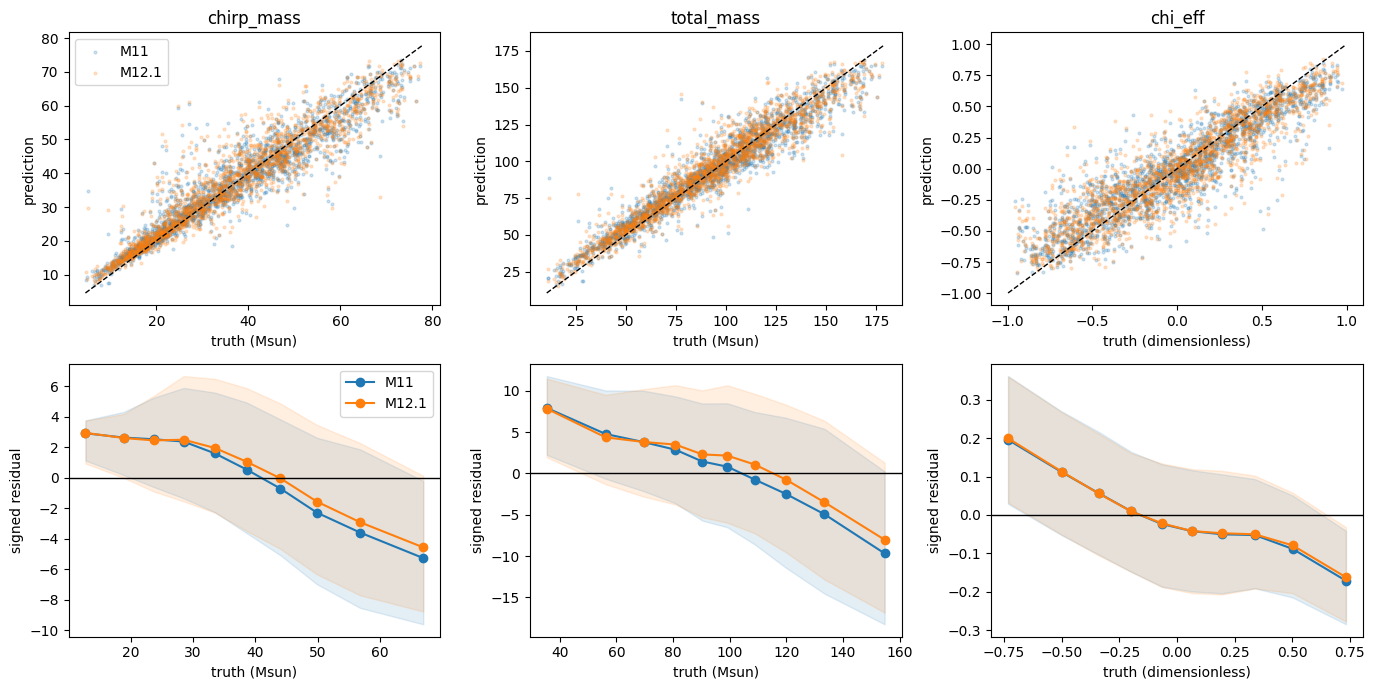

In [3]:
require((np.var(y_true, axis=0) > 0).all(), "OLS/R2 undefined for constant labels")
global_rows = []
for model, pred in predictions.items():
    table = regression_metrics(y_true, pred, LABELS, split_name="val").set_index("label")
    for j,label in enumerate(LABELS):
        slope, intercept = np.polyfit(y_true[:,j], pred[:,j], 1)
        global_rows.append(dict(model=model, label=label, unit=UNITS[j], n=len(val_ids),
            **table.loc[label, ["RMSE","MAE","R2","bias"]].to_dict(),
            slope=slope, intercept=intercept, slope_distance=abs(slope-1)))
global_metrics = pd.DataFrame(global_rows)
g0 = global_metrics[global_metrics.model.eq("M11")].set_index("label").reindex(LABELS)
g1 = global_metrics[global_metrics.model.eq("M12.1")].set_index("label").reindex(LABELS)
global_delta = g1[["RMSE","MAE","R2","bias","slope_distance"]] - g0[["RMSE","MAE","R2","bias","slope_distance"]]
global_delta.columns = ["delta_"+c for c in global_delta.columns]
global_delta["relative_RMSE_change"] = np.where(g0.RMSE > 0, global_delta.delta_RMSE / g0.RMSE, np.nan)
display(global_metrics)
display(global_delta)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
chosen = np.linspace(0, len(val_ids)-1, min(2000,len(val_ids)), dtype=int)
for j,label in enumerate(LABELS):
    lo = min(y_true[:,j].min(), *(p[:,j].min() for p in predictions.values()))
    hi = max(y_true[:,j].max(), *(p[:,j].max() for p in predictions.values()))
    axes[0,j].plot([lo,hi], [lo,hi], "k--", linewidth=1)
    edges = np.unique(np.quantile(y_true[:,j], np.linspace(0,1,11)))
    groups = np.searchsorted(edges[1:-1], y_true[:,j], side="right")
    for model in MODELS:
        axes[0,j].scatter(y_true[chosen,j], predictions[model][chosen,j], s=4, alpha=.2, label=model)
        centers, means, lower, upper = [], [], [], []
        for b in range(len(edges)-1):
            mask = groups == b
            if mask.sum() >= MIN_COUNT:
                r = residuals[model][mask,j]
                centers.append(y_true[mask,j].mean()); means.append(r.mean())
                lower.append(np.quantile(r,.16)); upper.append(np.quantile(r,.84))
        line, = axes[1,j].plot(centers,means,"o-",label=model)
        axes[1,j].fill_between(centers,lower,upper,color=line.get_color(),alpha=.12)
    axes[0,j].set(title=label, xlabel=f"truth ({UNITS[j]})", ylabel="prediction")
    axes[1,j].axhline(0,color="black",linewidth=1)
    axes[1,j].set(xlabel=f"truth ({UNITS[j]})", ylabel="signed residual")
axes[0,0].legend(); axes[1,0].legend()
fig.tight_layout(); plt.show()

## 3. Q10/Q90 tail behavior
Compute linear Q10/Q90 from **validation truth**, once per label. Lower = truth ≤ Q10; upper = truth ≥ Q90, including ties. Use identical masks for both models. Report count, signed bias, absolute signed-bias magnitude, and MAE. These are evaluation diagnostics only; neither these thresholds nor validation labels influence training weights. Opposite tail biases must not cancel. Slope-distance changes appear alongside global metrics and in acceptance.

In [4]:
thresholds = np.quantile(y_true, [.1,.9], axis=0)
tail_masks = {"lower":y_true <= thresholds[0], "upper":y_true >= thresholds[1]}
tail_rows = []
for j,label in enumerate(LABELS):
    for t,tail in enumerate(("lower","upper")):
        mask = tail_masks[tail][:,j]
        r0, r1 = residuals["M11"][mask,j], residuals["M12.1"][mask,j]
        tail_rows.append(dict(label=label, tail=tail, threshold=thresholds[t,j], n=int(mask.sum()),
            M11_bias=r0.mean(), M12_bias=r1.mean(), M11_MAE=np.abs(r0).mean(), M12_MAE=np.abs(r1).mean(),
            delta_abs_bias=abs(r1.mean())-abs(r0.mean()), delta_MAE=np.abs(r1).mean()-np.abs(r0).mean()))
tails = pd.DataFrame(tail_rows)
display(tails)

,label,tail,threshold,n,M11_bias,M12_bias,M11_MAE,M12_MAE,delta_abs_bias,delta_MAE
0,chirp_mass,lower,16.351124,4000,2.922491,2.948652,2.965636,2.991768,0.026161,0.026133
1,chirp_mass,upper,61.013297,4000,-5.258440,-4.556152,5.795812,5.208116,-0.702288,-0.587696
2,total_mass,lower,48.156340,4000,7.925503,7.841341,8.447998,8.351668,-0.084162,-0.096329
3,total_mass,upper,141.954028,4000,-9.679648,-8.026015,11.072026,9.855675,-1.653633,-1.216351
4,chi_eff,lower,-0.592998,4000,0.195573,0.199365,0.204830,0.208550,0.003792,0.003720
5,chi_eff,upper,0.596297,4000,-0.170833,-0.161837,0.177302,0.170903,-0.008996,-0.006399


## 4. Global train-only Mahalanobis
Use M12.0's frozen μ, population σ, sample covariance and standardized-coordinate precision. Recompute train distances only to reconstruct its empirical CDF, and require the same sorted-distance hash. No evaluation covariance or percentile reference is fitted. Verify train moments/covariance against the saved contract before use. A numerical-library/hash discrepancy is an unresolved provenance issue; do not silently refit or relax it after seeing candidate results.

P(d) = 100 × fraction of train distances ≤ d (`searchsorted(..., side='right')`). Bins remain [0,20), [20,40), [40,60), [60,80), [80,100]. P80–P100 is peripheral. Counts need not be equal on validation. Conditional errors for n<30 are undefined, with counts retained. This is label-space Mahalanobis, not latent distance or marginal distance.

In [5]:
mu = np.asarray(geometry["mean"],dtype=float)
sigma = np.asarray(geometry["std_ddof0"],dtype=float)
precision = np.asarray(geometry["precision"],dtype=float)
require(mu.shape == sigma.shape == (3,) and precision.shape == (3,3)
        and np.isfinite(mu).all() and np.isfinite(sigma).all()
        and (sigma > 0).all() and np.isfinite(precision).all(), "Invalid frozen geometry")
np.testing.assert_allclose(train_y.mean(axis=0), mu, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(train_y.std(axis=0), sigma, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(np.cov(train_y,rowvar=False,ddof=1), geometry["covariance_ddof1"], rtol=1e-12, atol=1e-12)
def distance(values):
    z = (values-mu)/sigma
    squared = np.einsum("ni,ij,nj->n",z,precision,z)
    require(np.isfinite(squared).all() and (squared >= -1e-10).all(), "Invalid distance")
    return np.sqrt(np.maximum(squared,0))
reference_distances = np.sort(distance(train_y))
require(array_hash(reference_distances) == geometry["reference_distance_sha256"], "Train reference hash mismatch")
mahal_pct = 100*np.searchsorted(reference_distances,distance(y_true),side="right")/len(train_y)
require(np.isfinite(mahal_pct).all() and ((mahal_pct >= 0) & (mahal_pct <= 100)).all(), "Invalid percentiles")

def bin_masks(values, edges):
    return [(values >= lo) & ((values <= hi) if b == len(edges)-2 else (values < hi))
            for b,(lo,hi) in enumerate(zip(edges[:-1],edges[1:]))]

def compare_mask(mask, j, min_count=MIN_COUNT):
    n = int(mask.sum())
    row = dict(n=n, supported=n >= min_count)
    for model, prefix in (("M11","M11"),("M12.1","M12")):
        r = residuals[model][mask,j]
        row[prefix+"_RMSE"] = float(np.sqrt(np.mean(r*r))) if n >= min_count else np.nan
        row[prefix+"_MAE"] = float(np.mean(np.abs(r))) if n >= min_count else np.nan
    row["delta_RMSE"] = row["M12_RMSE"]-row["M11_RMSE"]
    row["delta_MAE"] = row["M12_MAE"]-row["M11_MAE"]
    row["relative_RMSE_change"] = row["delta_RMSE"]/row["M11_RMSE"] if row["M11_RMSE"] > 0 else np.nan
    return row

def conditional(values, edges, dimension):
    masks = bin_masks(values,edges)
    return pd.DataFrame([dict(dimension=dimension, bin=b, lower=edges[b], upper=edges[b+1],
        upper_inclusive=b == len(edges)-2, label=label, **compare_mask(mask,j))
        for b,mask in enumerate(masks) for j,label in enumerate(LABELS)])

mahal_masks = bin_masks(mahal_pct,P_EDGES)
require((np.sum(mahal_masks,axis=0) == 1).all(), "Each validation row needs exactly one distance bin")
mahal_table = conditional(mahal_pct,P_EDGES,"global_mahalanobis_percentile")
require((mahal_table.groupby("label").n.sum().reindex(LABELS) == len(val_ids)).all(), "Incomplete distance counts")
peripheral = mahal_table[mahal_table.lower.eq(80)].set_index("label").reindex(LABELS)
display(mahal_table)

,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,M12_RMSE,M12_MAE,delta_RMSE,delta_MAE,relative_RMSE_change
0,global_mahalanobis_percentile,0,0.0,20.0,False,chirp_mass,8007,True,4.902952,3.623689,5.043911,3.769283,0.140960,0.145594,0.028750
1,global_mahalanobis_percentile,0,0.0,20.0,False,total_mass,8007,True,8.630829,6.346546,9.041258,6.743996,0.410429,0.397450,0.047554
2,global_mahalanobis_percentile,0,0.0,20.0,False,chi_eff,8007,True,0.157579,0.121417,0.158548,0.122858,0.000969,0.001442,0.006149
3,global_mahalanobis_percentile,1,20.0,40.0,False,chirp_mass,7957,True,5.342037,3.842708,5.274875,3.805945,-0.067162,-0.036764,-0.012572
4,global_mahalanobis_percentile,1,20.0,40.0,False,total_mass,7957,True,9.298274,6.800690,9.255271,6.824646,-0.043003,0.023956,-0.004625
5,global_mahalanobis_percentile,1,20.0,40.0,False,chi_eff,7957,True,0.167364,0.128352,0.169591,0.130354,0.002227,0.002002,0.013305
6,global_mahalanobis_percentile,2,40.0,60.0,False,chirp_mass,8045,True,5.453683,3.817659,5.316852,3.712046,-0.136830,-0.105613,-0.025090
7,global_mahalanobis_percentile,2,40.0,60.0,False,total_mass,8045,True,9.758866,7.126635,9.435087,6.875484,-0.323779,-0.251150,-0.033178
8,global_mahalanobis_percentile,2,40.0,60.0,False,chi_eff,8045,True,0.180632,0.136712,0.181862,0.137059,0.001230,0.000347,0.006811
9,global_mahalanobis_percentile,3,60.0,80.0,False,chirp_mass,7952,True,5.982311,3.973223,5.705259,3.829190,-0.277052,-0.144033,-0.046312


## 5. Network SNR
Use only the saved `final_network_snr`: synthetic optimal final network SNR, 30–512 Hz, with M12.0 edges [10,12.5,15,17.5,20,22.5,25]. No catalog, requested, or recomputed SNR substitution. Nominal bins are left inclusive and final upper inclusive. Explicit under/overflow rows ensure every validation row is accounted for; all remain in global metrics. Low SNR below denotes [10,12.5), with out-of-range values reported separately. Global differences are in section 2; this table exposes their SNR dependence.

In [6]:
snr_table = pd.DataFrame()
low_snr = pd.DataFrame()
if snr is None:
    print("UNRESOLVED SNR:", snr_issue)
else:
    snr_table = conditional(snr,SNR_EDGES,"final_network_snr")
    outside = pd.DataFrame([dict(dimension="final_network_snr",bin=name, label=label,
        **compare_mask(mask,j)) for name,mask in (("below_10",snr < 10),("above_25",snr > 25))
        for j,label in enumerate(LABELS)])
    snr_table = pd.concat([snr_table,outside],ignore_index=True)
    require((snr_table.groupby("label").n.sum().reindex(LABELS) == len(val_ids)).all(), "Incomplete SNR counts")
    low_snr = snr_table[snr_table.bin.eq(0)].set_index("label").reindex(LABELS)
    display(snr_table)

,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,M12_RMSE,M12_MAE,delta_RMSE,delta_MAE,relative_RMSE_change
0,final_network_snr,0,10.0,12.5,False,chirp_mass,6757,True,7.949685,5.582626,7.873660,5.602394,-0.076025,0.019768,-0.009563
1,final_network_snr,0,10.0,12.5,False,total_mass,6757,True,14.979980,10.979815,14.931857,11.052351,-0.048123,0.072536,-0.003212
2,final_network_snr,0,10.0,12.5,False,chi_eff,6757,True,0.261345,0.203745,0.261414,0.204278,0.000070,0.000533,0.000267
3,final_network_snr,1,12.5,15.0,False,chirp_mass,6711,True,6.848787,4.743865,6.785508,4.693186,-0.063280,-0.050679,-0.009240
4,final_network_snr,1,12.5,15.0,False,total_mass,6711,True,12.570757,8.978671,12.364729,8.964175,-0.206028,-0.014496,-0.016389
5,final_network_snr,1,12.5,15.0,False,chi_eff,6711,True,0.225583,0.171863,0.223445,0.171109,-0.002138,-0.000755,-0.009479
6,final_network_snr,2,15.0,17.5,False,chirp_mass,6636,True,5.742407,3.955851,5.713259,3.919308,-0.029148,-0.036543,-0.005076
7,final_network_snr,2,15.0,17.5,False,total_mass,6636,True,10.025744,7.459881,9.896062,7.364110,-0.129682,-0.095771,-0.012935
8,final_network_snr,2,15.0,17.5,False,chi_eff,6636,True,0.192272,0.145999,0.192102,0.146443,-0.000170,0.000443,-0.000884
9,final_network_snr,3,17.5,20.0,False,chirp_mass,6625,True,4.924411,3.425289,4.991703,3.455960,0.067292,0.030671,0.013665


## 6. New diagnostic only: marginal label peripherality
For each label k, define a_k = |y_k − μ_train,k| / σ_train,k with the same physical train mean and population standard deviation. Each marginal CDF is fitted solely to that label's train absolute distances, with right-side ranks including ties. Apply it to validation truth, never predictions. This distinguishes marginal extremes from joint Mahalanobis geometry but folds positive/negative tails together; retain section 3 for their signs.

Use the same fixed percentile edges for every marginal reference. `marginal_table` includes all three prediction errors against each of the three marginal coordinates; `own_periphery` selects matching error/coordinate labels. Highlight mass errors against chi_eff peripherality with one 1×2 plot. Cross-label relationships may reflect correlated target distributions, SNR or waveform identifiability. They are **descriptive associations, not causal evidence of multi-task interference**.

At most two coarse 2×2 summaries are allowed: each mass's own P80 split × chi_eff's P80 split. Only calculate errors if **all four cells contain at least 100 rows**; otherwise show support counts and skip that summary. No outcome-driven bin refinement or loss/weight changes are allowed for the current M12.1 experiment.

,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,M12_RMSE,M12_MAE,delta_RMSE,delta_MAE,relative_RMSE_change,reference_label
0,chirp_mass,0,0.0,20.0,False,chirp_mass,7912,True,5.095718,3.642738,5.497495,3.977972,0.401778,0.335234,0.078846,chirp_mass
3,chirp_mass,1,20.0,40.0,False,chirp_mass,7928,True,5.449723,3.830882,5.652469,3.987652,0.202746,0.156771,0.037203,chirp_mass
6,chirp_mass,2,40.0,60.0,False,chirp_mass,8165,True,5.651507,3.863706,5.666947,3.787221,0.015441,-0.076485,0.002732,chirp_mass
9,chirp_mass,3,60.0,80.0,False,chirp_mass,8074,True,5.849986,3.812921,5.774316,3.678010,-0.075670,-0.134911,-0.012935,chirp_mass
12,chirp_mass,4,80.0,100.0,True,chirp_mass,7921,True,6.929244,4.602003,6.360593,4.271071,-0.568651,-0.330932,-0.082065,chirp_mass
16,total_mass,0,0.0,20.0,False,total_mass,7969,True,9.160533,6.511800,10.014958,7.201736,0.854425,0.689936,0.093272,total_mass
19,total_mass,1,20.0,40.0,False,total_mass,7961,True,9.253008,6.633318,9.704944,7.094675,0.451936,0.461357,0.048842,total_mass
22,total_mass,2,40.0,60.0,False,total_mass,8004,True,9.517805,7.085091,9.465297,7.005247,-0.052508,-0.079844,-0.005517,total_mass
25,total_mass,3,60.0,80.0,False,total_mass,8127,True,10.383890,7.722701,9.845672,7.248703,-0.538218,-0.473998,-0.051832,total_mass
28,total_mass,4,80.0,100.0,True,total_mass,7939,True,13.930931,9.771142,13.029999,9.116091,-0.900932,-0.655051,-0.064671,total_mass


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,M12_RMSE,M12_MAE,delta_RMSE,delta_MAE,relative_RMSE_change,reference_label
1,chirp_mass,0,0.0,20.0,False,total_mass,7912,True,8.487750,6.188167,9.261181,6.844129,0.773431,0.655962,0.091123,chirp_mass
2,chirp_mass,0,0.0,20.0,False,chi_eff,7912,True,0.170752,0.130116,0.174107,0.132861,0.003355,0.002745,0.019650,chirp_mass
4,chirp_mass,1,20.0,40.0,False,total_mass,7928,True,9.033148,6.581467,9.423185,6.920786,0.390037,0.339319,0.043178,chirp_mass
5,chirp_mass,1,20.0,40.0,False,chi_eff,7928,True,0.172705,0.132812,0.174755,0.134246,0.002049,0.001433,0.011866,chirp_mass
7,chirp_mass,2,40.0,60.0,False,total_mass,8165,True,9.767927,7.239747,9.692788,7.046129,-0.075139,-0.193618,-0.007692,chirp_mass
8,chirp_mass,2,40.0,60.0,False,chi_eff,8165,True,0.183597,0.138740,0.183105,0.138784,-0.000491,0.000043,-0.002677,chirp_mass
10,chirp_mass,3,60.0,80.0,False,total_mass,8074,True,10.587431,7.848113,10.308940,7.600728,-0.278491,-0.247385,-0.026304,chirp_mass
11,chirp_mass,3,60.0,80.0,False,chi_eff,8074,True,0.197078,0.147099,0.194699,0.145316,-0.002379,-0.001784,-0.012069,chirp_mass
13,chirp_mass,4,80.0,100.0,True,total_mass,7921,True,14.174385,9.863410,13.266735,9.254580,-0.907650,-0.608831,-0.064035,chirp_mass
14,chirp_mass,4,80.0,100.0,True,chi_eff,7921,True,0.239565,0.177786,0.237335,0.177724,-0.002230,-0.000062,-0.009309,chirp_mass


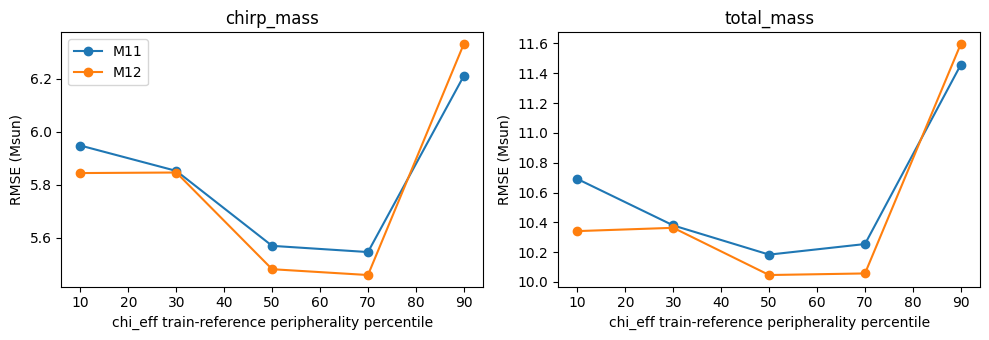

,label,mass_P80,chi_eff_P80,n
0,chirp_mass,False,False,25682
1,chirp_mass,False,True,6397
2,chirp_mass,True,False,6480
3,chirp_mass,True,True,1441
4,total_mass,False,False,25594
5,total_mass,False,True,6467
6,total_mass,True,False,6568
7,total_mass,True,True,1371


,label,mass_P80,chi_eff_P80,n,supported,M11_RMSE,M11_MAE,M12_RMSE,M12_MAE,delta_RMSE,delta_MAE,relative_RMSE_change
0,chirp_mass,False,False,25682,True,5.387912,3.739828,5.487843,3.784182,0.099931,0.044354,0.018547
1,chirp_mass,False,True,6397,True,6.028209,3.982961,6.256405,4.145909,0.228196,0.162948,0.037855
2,chirp_mass,True,False,6480,True,6.921231,4.638316,6.292859,4.288417,-0.628372,-0.349899,-0.090789
3,chirp_mass,True,True,1441,True,6.965160,4.438711,6.656671,4.193070,-0.308489,-0.245641,-0.044290
4,total_mass,False,False,25594,True,9.267604,6.763812,9.380108,6.868207,0.112505,0.104395,0.012140
5,total_mass,False,True,6467,True,10.793940,7.895286,11.136705,8.205761,0.342766,0.310475,0.031755
6,total_mass,True,False,6568,True,13.879541,9.705829,12.916832,9.041333,-0.962709,-0.664496,-0.069362
7,total_mass,True,True,1371,True,14.174539,10.084035,13.559051,9.474232,-0.615489,-0.609804,-0.043422


In [7]:
marginal_pct = np.empty_like(y_true)
marginal_reference_hashes = {}
for j,label in enumerate(LABELS):
    reference = np.sort(np.abs((train_y[:,j]-mu[j])/sigma[j]))
    query = np.abs((y_true[:,j]-mu[j])/sigma[j])
    marginal_pct[:,j] = 100*np.searchsorted(reference,query,side="right")/len(reference)
    marginal_reference_hashes[label] = array_hash(reference)
require(np.isfinite(marginal_pct).all() and ((marginal_pct >= 0) & (marginal_pct <= 100)).all(), "Marginal percentile bounds")
for j in range(3):
    require((np.sum(bin_masks(marginal_pct[:,j],P_EDGES),axis=0) == 1).all(), "Marginal bin assignment")
marginal_table = pd.concat([conditional(marginal_pct[:,j],P_EDGES,label).assign(reference_label=label)
                           for j,label in enumerate(LABELS)],ignore_index=True)
require((marginal_table.groupby(["reference_label","label"]).n.sum() == len(val_ids)).all(), "Marginal counts")
own_periphery = marginal_table[marginal_table.reference_label.eq(marginal_table.label)]
cross_label = marginal_table[~marginal_table.reference_label.eq(marginal_table.label)]
display(own_periphery)
display(cross_label)
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax,label in zip(axes,LABELS[:2]):
    sub = marginal_table[marginal_table.reference_label.eq("chi_eff") & marginal_table.label.eq(label)]
    for prefix in ("M11","M12"):
        ax.plot((sub.lower+sub.upper)/2,sub[prefix+"_RMSE"],"o-",label=prefix)
    ax.set(title=label, xlabel="chi_eff train-reference peripherality percentile", ylabel="RMSE (Msun)")
axes[0].legend(); fig.tight_layout(); plt.show()

summaries_2d, support_2d = [], []
for j,label in enumerate(LABELS[:2]):
    masks = [(a,b, ((marginal_pct[:,j] >= 80) == a) & ((marginal_pct[:,2] >= 80) == b))
             for a in (False,True) for b in (False,True)]
    support_2d.extend(dict(label=label, mass_P80=a, chi_eff_P80=b, n=int(mask.sum())) for a,b,mask in masks)
    if all(mask.sum() >= MIN_2D_COUNT for _,_,mask in masks):
        summaries_2d.extend(dict(label=label, mass_P80=a, chi_eff_P80=b,
            **compare_mask(mask,j,MIN_2D_COUNT)) for a,b,mask in masks)
    else:
        print("2D error summary skipped for inadequate support:",label)
display(pd.DataFrame(support_2d))
if summaries_2d:
    display(pd.DataFrame(summaries_2d))
provenance["marginal_reference_hashes"] = marginal_reference_hashes
del train_y, reference_distances, reference  # no later cells need train-label arrays

## 7. Paired row bootstrap — separate manual opt-in
Default 400 replicates, seed 123; configurable before inspecting uncertainty results. Set `RUN_BOOTSTRAP=True` and manually execute the next cell to compute it. No bootstrap is executed during notebook creation, and its default state skips computation.

Each replicate draws N validation positions with replacement once, corresponding to identical original `val_ids` for both models and all labels. Compute paired deltas for RMSE, |slope−1|, and |lower/upper-tail mean residual|. Tail thresholds remain the original validation Q10/Q90: resampling varies the rows and tail counts, not the diagnostic definitions. This gives uncertainty conditional on those thresholds and these trained checkpoints. Tail MAE remains a point diagnostic. Undefined replicates are counted, not silently assigned zero; with insufficient valid replicates intervals are withheld.

Report central 95% percentile intervals of the paired differences. Negative differences favor M12.1 for these metrics. These are marginal intervals, without a multiple-comparison adjustment; they exclude training-seed variation and are not independent evidence after validation-based checkpoint selection. Row bootstrap assumes independent rows. Repeated astrophysical sources would require source-group resampling; the inspected artifacts establish row IDs, not that source mapping. Do not describe row-bootstrap precision as source-independent uncertainty until that limitation is resolved. Only one replicate's sampled arrays is held at a time, not a B×N×labels tensor.

In [8]:
bootstrap_summary = pd.DataFrame()
bootstrap_deltas = None
bootstrap_metrics = ["RMSE", "slope_distance", "lower_abs_bias", "upper_abs_bias"]

def bootstrap_statistics(positions):
    truth = y_true[positions]
    centered = truth-truth.mean(axis=0)
    ss = np.sum(centered*centered,axis=0)
    stats = []
    for model in MODELS:
        pred = predictions[model][positions]
        r = pred-truth
        rmse = np.sqrt(np.mean(r*r,axis=0))
        slope = np.divide(np.sum(centered*pred,axis=0),ss,
                          out=np.full(3,np.nan),where=ss > 0)
        tail_bias = []
        for tail in ("lower","upper"):
            mask = tail_masks[tail][positions]
            counts = mask.sum(axis=0)
            bias = np.divide(np.sum(r*mask,axis=0),counts,
                             out=np.full(3,np.nan),where=counts > 0)
            tail_bias.append(np.abs(bias))
        stats.append(np.column_stack([rmse,abs(slope-1),*tail_bias]))
    return stats[1]-stats[0]

if RUN_BOOTSTRAP:
    require(isinstance(BOOTSTRAP_COUNT,int) and BOOTSTRAP_COUNT >= 100, "Use at least 100 replicates; default 400")
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    bootstrap_deltas = np.empty((BOOTSTRAP_COUNT,3,4),dtype=float)
    for b in range(BOOTSTRAP_COUNT):
        positions = rng.integers(0,len(val_ids),size=len(val_ids))
        bootstrap_deltas[b] = bootstrap_statistics(positions)
    points = bootstrap_statistics(np.arange(len(val_ids)))
    rows = []
    for j,label in enumerate(LABELS):
        for k,metric in enumerate(bootstrap_metrics):
            samples = bootstrap_deltas[:,j,k]
            valid = samples[np.isfinite(samples)]
            sufficient = len(valid) >= max(100,int(np.ceil(.95*BOOTSTRAP_COUNT)))
            lo,hi = np.quantile(valid,[.025,.975]) if sufficient else (np.nan,np.nan)
            rows.append(dict(label=label,metric=metric,delta=points[j,k],ci_low=lo,ci_high=hi,
                n_valid=len(valid),n_invalid=BOOTSTRAP_COUNT-len(valid),seed=BOOTSTRAP_SEED,
                supported=sufficient))
    bootstrap_summary = pd.DataFrame(rows)
    display(bootstrap_summary)
else:
    print("Bootstrap not run. Set RUN_BOOTSTRAP=True and explicitly run this cell when ready.")

,label,metric,delta,ci_low,ci_high,n_valid,n_invalid,seed,supported
0,chirp_mass,RMSE,-0.030144,-0.085300,0.022157,400,0,123,True
1,chirp_mass,slope_distance,-0.017052,-0.018662,-0.015811,400,0,123,True
2,chirp_mass,lower_abs_bias,0.026161,-0.034386,0.087016,400,0,123,True
3,chirp_mass,upper_abs_bias,-0.702288,-0.802416,-0.609499,400,0,123,True
4,total_mass,RMSE,-0.107324,-0.242365,0.009786,400,0,123,True
5,total_mass,slope_distance,-0.019780,-0.021360,-0.018388,400,0,123,True
6,total_mass,lower_abs_bias,-0.084162,-0.237816,0.093213,400,0,123,True
7,total_mass,upper_abs_bias,-1.653633,-1.829709,-1.472937,400,0,123,True
8,chi_eff,RMSE,-0.000169,-0.001139,0.001017,400,0,123,True
9,chi_eff,slope_distance,-0.004743,-0.006539,-0.002987,400,0,123,True


## 8. Provisional acceptance — separate criteria, no overall score
Use candidate minus baseline deltas. The **provisional maximum global RMSE degradation is 2% for each label**. Both masses should improve slope distance from one and absolute Q10 and Q90 signed-bias magnitudes, separately. Peripheral P80–P100 RMSE should improve for at least one mass without material deterioration in the other. The numerical definition of *material* remains unspecified (`PERIPHERAL_MASS_MAX_DEGRADATION=None`), so that combined peripheral requirement remains unresolved. Set any tolerance prospectively, not after viewing outcomes.

Assess chi_eff and [10,12.5) low-SNR changes separately; do not hide them behind mass gains. Inspect SNR under/overflow as well. No arbitrary cross-label score or automated overall acceptance is produced. Point-direction flags are not evidence of significant improvement. Bootstrap intervals (when requested) distinguish negative-direction support from uncertainty; an interval crossing zero is inconclusive. Peripheral and SNR changes here have no bootstrap intervals and cannot be claimed significant from point estimates alone. The 2% threshold is provisional; uncertainty, source dependence, label tradeoffs, and validation selection remain part of the scientific decision.

The marginal/cross-label analyses provide explanatory hypotheses only. They neither change the current weighted loss nor justify post-hoc tuning of its alpha or reference definition. No final test, calibration, or real-event evaluation is performed.

In [10]:
def interval_for(label, metric):
    if bootstrap_summary.empty:
        return dict(ci_low=np.nan,ci_high=np.nan,uncertainty="not computed")
    row = bootstrap_summary[(bootstrap_summary.label == label) & (bootstrap_summary.metric == metric)].iloc[0]
    return dict(ci_low=row.ci_low,ci_high=row.ci_high,
        uncertainty="negative delta supported" if row.ci_high < 0 else
                    "nonnegative delta supported" if row.ci_low >= 0 else "inconclusive/undefined")

acceptance_rows = []
for label in LABELS:
    rel = global_delta.loc[label,"relative_RMSE_change"]
    acceptance_rows.append(dict(label=label,criterion="global RMSE guardrail",delta=global_delta.loc[label,"delta_RMSE"],
        relative_change=rel,point_status="within provisional 2%" if rel <= .02 else
            "exceeds provisional 2%" if np.isfinite(rel) else "undefined baseline RMSE",
        **interval_for(label,"RMSE")))
    for metric in ("slope_distance","lower_abs_bias","upper_abs_bias"):
        if metric == "slope_distance":
            delta = global_delta.loc[label,"delta_slope_distance"]
        else:
            tail = metric.split("_")[0]
            delta = tails.loc[tails["tail"].eq(tail) & tails["tail"].eq(tail),"delta_abs_bias"].iloc[0]
        acceptance_rows.append(dict(label=label,criterion=metric,delta=delta,
            role="required mass improvement" if label in LABELS[:2] else "separate chi_eff assessment",
            point_status="improved" if delta < 0 else "not improved",**interval_for(label,metric)))
acceptance_table = pd.DataFrame(acceptance_rows)
display(acceptance_table)
display(peripheral[["n","supported","M11_RMSE","M12_RMSE","delta_RMSE","relative_RMSE_change"]])
mass_peripheral = peripheral.loc[LABELS[:2]]
if not mass_peripheral.supported.all() or not np.isfinite(mass_peripheral.relative_RMSE_change).all():
    peripheral_status = "Unresolved: insufficient peripheral support or undefined reference RMSE"
elif PERIPHERAL_MASS_MAX_DEGRADATION is None:
    peripheral_status = "Unresolved: define material deterioration prospectively; inspect both mass deltas"
else:
    require(np.isfinite(PERIPHERAL_MASS_MAX_DEGRADATION) and PERIPHERAL_MASS_MAX_DEGRADATION >= 0,
            "Peripheral deterioration tolerance must be a nonnegative fraction")
    point_ok = ((mass_peripheral.delta_RMSE < 0).any()
                and (mass_peripheral.relative_RMSE_change <= PERIPHERAL_MASS_MAX_DEGRADATION).all())
    peripheral_status = "Peripheral point criterion met" if point_ok else "Peripheral point criterion not met"
print(peripheral_status)
print("Separate chi_eff global/tail/peripheral review required; no overall score.")
if not low_snr.empty:
    display(low_snr[["n","supported","M11_RMSE","M12_RMSE","delta_RMSE","delta_MAE","relative_RMSE_change"]])
else:
    print("Low-SNR assessment unresolved:",snr_issue)
# Compact in-memory summary, no arrays duplicated and no files written.
evaluation_summary = dict(split="val",provenance=provenance,
    global_metrics=global_metrics.to_dict("records"),global_deltas=global_delta.reset_index().to_dict("records"),
    tails=tails.to_dict("records"),acceptance=acceptance_table.to_dict("records"),
    peripheral_status=peripheral_status,bootstrap_count=BOOTSTRAP_COUNT if RUN_BOOTSTRAP else 0,
    bootstrap_seed=BOOTSTRAP_SEED,overall_decision=None)

,label,criterion,delta,relative_change,point_status,ci_low,ci_high,uncertainty,role
0,chirp_mass,global RMSE guardrail,-0.030144,-0.005173,within provisional 2%,-0.085300,0.022157,inconclusive/undefined,NaN
1,chirp_mass,slope_distance,-0.017052,NaN,improved,-0.018662,-0.015811,negative delta supported,required mass improvement
2,chirp_mass,lower_abs_bias,0.026161,NaN,not improved,-0.034386,0.087016,inconclusive/undefined,required mass improvement
3,chirp_mass,upper_abs_bias,-0.702288,NaN,improved,-0.802416,-0.609499,negative delta supported,required mass improvement
4,total_mass,global RMSE guardrail,-0.107324,-0.010127,within provisional 2%,-0.242365,0.009786,inconclusive/undefined,NaN
5,total_mass,slope_distance,-0.019780,NaN,improved,-0.021360,-0.018388,negative delta supported,required mass improvement
6,total_mass,lower_abs_bias,0.026161,NaN,not improved,-0.237816,0.093213,inconclusive/undefined,required mass improvement
7,total_mass,upper_abs_bias,-0.702288,NaN,improved,-1.829709,-1.472937,negative delta supported,required mass improvement
8,chi_eff,global RMSE guardrail,-0.000169,-0.000867,within provisional 2%,-0.001139,0.001017,inconclusive/undefined,NaN
9,chi_eff,slope_distance,-0.004743,NaN,improved,-0.006539,-0.002987,negative delta supported,separate chi_eff assessment


,n,supported,M11_RMSE,M12_RMSE,delta_RMSE,relative_RMSE_change
label,,,,,,
chirp_mass,8039,True,7.184116,7.338602,0.154485,0.021504
total_mass,8039,True,13.378729,13.376794,-0.001936,-0.000145
chi_eff,8039,True,0.246372,0.244473,-0.001899,-0.007710


Peripheral point criterion not met
Separate chi_eff global/tail/peripheral review required; no overall score.


,n,supported,M11_RMSE,M12_RMSE,delta_RMSE,delta_MAE,relative_RMSE_change
label,,,,,,,
chirp_mass,6757,True,7.949685,7.873660,-0.076025,0.019768,-0.009563
total_mass,6757,True,14.979980,14.931857,-0.048123,0.072536,-0.003212
chi_eff,6757,True,0.261345,0.261414,0.000070,0.000533,0.000267


## 9. Scientific conclusions — M12.1 weighted MSE

### 9.1. Experimental scope

M12.1 evaluated whether a moderate sample-weighted MSE based on the global Mahalanobis distance in label space can reduce regression-to-the-mean in the frozen M11 predictor.

The experiment used the unchanged G1 dataset, train/validation splits, input preprocessing and normalization, target scaling, CNN architecture, optimizer and training configuration. The only intended intervention was the training objective, with train-only Mahalanobis percentile weights and $\alpha=0.5$, normalized to unit mean.

The analysis compares the frozen M11 checkpoint with the M12.1 checkpoint selected at epoch 51, using the same 40,000 validation samples. Calibration, test and real-event datasets were excluded from candidate assessment.

### 9.2. Main findings

**Global predictive accuracy.** M12.1 achieved small reductions in validation RMSE for chirp mass (−0.52%), total mass (−1.01%) and effective spin (−0.09%). All three parameters satisfy the provisional 2% RMSE degradation guardrail. However, paired bootstrap confidence intervals for the global RMSE differences include zero, so the improvements in average predictive accuracy are not conclusive.

**Regression-to-the-mean.** Prediction slopes increased from 0.8351 to 0.8522 for chirp mass, from 0.8593 to 0.8791 for total mass, and from 0.7760 to 0.7808 for effective spin. The paired bootstrap intervals support reductions in slope distance from one for all three labels, conditional on the evaluated checkpoints. This demonstrates that the weighting intervention modifies the predictor's global contraction behavior in the intended direction.

**Tail bias.** Improvements are strongly asymmetric. Upper-tail Q90 underestimation decreases for both mass parameters: chirp mass bias changes from −5.258 to −4.556 solar masses, and total mass bias from −9.680 to −8.026 solar masses. These reductions are supported by paired bootstrap intervals. Conversely, the lower-tail Q10 biases show little improvement: chirp mass deteriorates slightly, total mass improves only marginally, and effective-spin lower-tail bias increases.

**Global Mahalanobis conditioning.** Weighted MSE produces its clearest reductions in mass RMSE within the P40–P80 Mahalanobis percentile range. In the central P0–P20 region, both mass parameters deteriorate. In the most peripheral P80–P100 region, chirp mass RMSE increases by approximately 2.15%, whereas total mass remains effectively unchanged. Consequently, the intervention does not establish a systematic improvement in the most peripheral joint-label regions.

**SNR conditioning.** The lowest-SNR bin, [10,12.5), shows small RMSE improvements for both mass parameters, with nearly unchanged effective-spin RMSE. No clear general improvement restricted to low SNR is established.

### 9.3. Marginal and cross-label peripherality

The exploratory marginal-peripherality analysis provides evidence that the effectiveness of the global weighting depends on which parameter is extreme.

When a mass parameter is peripheral but effective spin is not, M12.1 produces comparatively large mass-RMSE improvements. Conversely, in samples with central mass and peripheral effective spin, mass prediction errors can increase.

These observations suggest that applying a single sample weight to all three regression losses may not be optimal. A globally peripheral system does not necessarily require increased emphasis on every individual parameter.

This result motivates a subsequent experiment using parameter-specific weights:

\[
w_{ik} =
\frac{1+\alpha F_{k,\mathrm{train}}(|y_{ik}-\mu_k|/\sigma_k)}
{\operatorname{mean}_{j\in\mathrm{train}}[1+\alpha F_{k,\mathrm{train}}(|y_{jk}-\mu_k|/\sigma_k)]},
\]

with the weighted loss applied independently to each target.

The marginal diagnostic results remain exploratory and must not be interpreted as direct evidence of gradient conflict or negative transfer between tasks.

### 9.4. Interpretation and limitations

M12.1 provides evidence that moderate peripherality weighting can reduce global prediction contraction without a material increase in average validation error.

Nevertheless, the improvement is not uniform across parameter space. It preferentially reduces high-mass underestimation while leaving low-mass overestimation largely unresolved. It also fails to improve the extreme global-Mahalanobis region consistently.

Moreover, global signed biases increase for both mass parameters, indicating that reduced prediction slope compression does not automatically imply improved overall centering.

The paired bootstrap characterizes sampling uncertainty on the frozen validation set for the two fitted checkpoints. It does not establish reproducibility across independent training seeds, nor does it demonstrate transfer to real gravitational-wave events.

### 9.5. Acceptance assessment

The predefined global RMSE guardrail is satisfied, and the slope criterion is met for both mass parameters.

However, the lower-tail bias requirement is not fully satisfied, and the extreme global-Mahalanobis performance criterion is not met. The effective-spin results also show mixed effects, particularly in the lower tail.

**M12.1 is therefore classified as a partially successful intervention, but not an accepted replacement for the frozen M11 baseline.**

### 9.6. Next research steps

The next scientific priority is to compare global weighting against a parameter-specific marginal weighting strategy, while preserving G1, architecture, training budget and evaluation protocols.

Before committing to another expensive training run, the two weighting schemes should be compared through a lightweight CPU-based analysis of their distributions, correlations and relative emphasis on each regression target.

If the marginal weighting produces a meaningfully different objective, a single controlled training run can test whether it improves low-mass bias and extreme peripherality more effectively than global weighting.

Balanced sampling remains a separate subsequent intervention. Architectural changes, including separate regression heads or a shared mass head with an effective-spin head, should be considered only after the loss-level experiments and relevant multi-task diagnostics.

**Final status:** M12.1 weighted-MSE training and validation analysis completed. No calibration, test or real-event conclusions are drawn. M11 remains the frozen reference model pending comparison with subsequent M12 candidates.